<a href="https://colab.research.google.com/github/khadijaZafar2511/edurisk-ai-student-performance-prediction/blob/main/EduGuard_AI_Student_Risk_Intelligence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Environment Setup


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from pathlib import Path

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("=" * 60)
print("EduGuard AI | Environment initialized")
print("=" * 60)

EduGuard AI | Environment initialized


 ## Data Acquisition

In [ ]:
from google.colab import files
uploaded= files.upload()


Saving StudentPerformanceFactors.csv to StudentPerformanceFactors.csv


In [ ]:

if not uploaded:
    raise ValueError("No dataset uploaded. Please upload a CSV file.")
file_name=next(iter(uploaded))
df_raw=pd.read_csv(file_name)
print("Dataset loaded successfully.")
print("File name",file_name)
print("Total Rows",df_raw.shape[0])
print("Total Columns",df_raw.shape[1])

Dataset loaded successfully.
File name StudentPerformanceFactors.csv
Total Rows 6607
Total Columns 20


## Schema Inspection


In [ ]:
print("--- Dataset Shape ---",df_raw.shape)
print("-- Column Names --",df_raw.columns.tolist())
print("--- Data Types ---")
display(df_raw.dtypes.to_frame(name="data_type"))
print("--Dataset Info",df_raw.info())
display(df_raw.head(5))


--- Dataset Shape --- (6607, 20)
-- Column Names -- ['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']
--- Data Types ---


,data_type
Hours_Studied,int64
Attendance,int64
Parental_Involvement,object
Access_to_Resources,object
Extracurricular_Activities,object
Sleep_Hours,int64
Previous_Scores,int64
Motivation_Level,object
Internet_Access,object
Tutoring_Sessions,int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


## Data quality audit

In [ ]:
quality_report=pd.DataFrame({
    "columns":df_raw.columns,
    "dtypes":df_raw.dtypes,
    "missing_count":df_raw.isnull().sum(),
    "missing_per":(df_raw.isnull().mean()*100).round(2),
    "unique_values":df_raw.nunique()
})

quality_report["duplicate_column_val"]=(quality_report["unique_values"]==1)

print("--Duplicate Rows--",df_raw.duplicated().sum())
print("--Total missing cells--",df_raw.isnull().sum().sum())

display(
    quality_report.sort_values(
        by="missing_per",
        ascending=False
    ).reset_index(drop=True)
)

--Duplicate Rows-- 0
--Total missing cells-- 235


,columns,dtypes,missing_count,missing_per,unique_values,duplicate_column_val
0,Parental_Education_Level,object,90,1.36,3,False
1,Teacher_Quality,object,78,1.18,3,False
2,Distance_from_Home,object,67,1.01,3,False
3,Hours_Studied,int64,0,0.00,41,False
4,Access_to_Resources,object,0,0.00,3,False
5,Parental_Involvement,object,0,0.00,3,False
6,Attendance,int64,0,0.00,41,False
7,Extracurricular_Activities,object,0,0.00,2,False
8,Motivation_Level,object,0,0.00,3,False
9,Internet_Access,object,0,0.00,2,False


## Statistical profiling

In [ ]:

numerical_cols=df_raw.select_dtypes(include=np.number).columns.to_list()
categorical_cols=df_raw.select_dtypes(exclude=np.number).columns.to_list()
print("Numeric columns:", numerical_cols)
print("\nCategorical / non-numeric columns:", categorical_cols)

Numeric columns: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']

Categorical / non-numeric columns: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']



## Exam Score Distribution



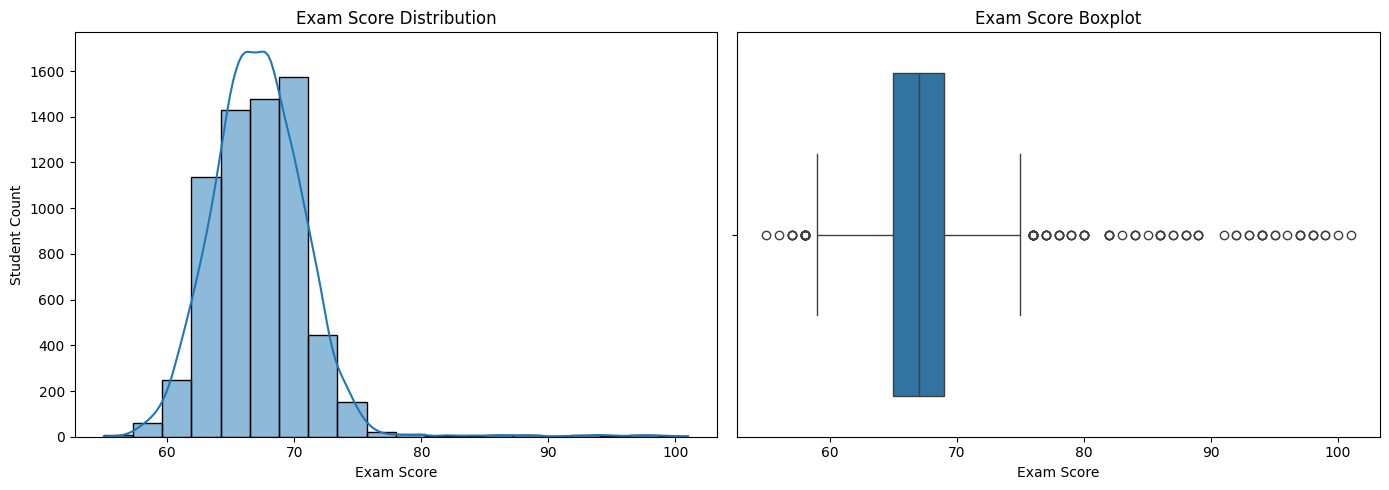

Score Statistics:
Mean:   67.24
Median: 67.00
Std:    3.89
Min:    55.00
Max:    101.00


In [ ]:



score_col = "Exam_Score"

if score_col not in df_raw.columns:
    raise KeyError(f"Required target column '{score_col}' not found.")

scores = df_raw[score_col].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution
sns.histplot(
    scores,
    bins=20,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Exam Score Distribution")
axes[0].set_xlabel("Exam Score")
axes[0].set_ylabel("Student Count")

# Boxplot
sns.boxplot(
    x=scores,
    ax=axes[1]
)
axes[1].set_title("Exam Score Boxplot")
axes[1].set_xlabel("Exam Score")

plt.tight_layout()
plt.show()

print("Score Statistics:")
print(f"Mean:   {scores.mean():.2f}")
print(f"Median: {scores.median():.2f}")
print(f"Std:    {scores.std():.2f}")
print(f"Min:    {scores.min():.2f}")
print(f"Max:    {scores.max():.2f}")

In [ ]:
pass_threshold=65
df_raw["Pass_Fail"]=(df_raw["Exam_Score"]>=pass_threshold).astype(int)
display(df_raw[["Exam_Score", "Pass_Fail"]].head().style.hide(axis="index"))


Exam_Score,Pass_Fail
67,1
61,0
74,1
71,1
70,1


## Categorical Inspection / Audit


In [ ]:
for col in categorical_cols:
  # print("Feature",col)
  # print("Unique Values",df_raw[col].nunique())
  # print(df_raw[col].value_counts())

  non_null_values=df_raw[col].dropna()
  whitespace_values=non_null_values[non_null_values!=non_null_values.str.strip()]
  case_variants=non_null_values.groupby(non_null_values.str.strip().str.lower()).unique()
  case_variants = {
        key: values
        for key, values in case_variants.items()
        if len(values) > 1
    }

  print("Whitespace issues:")
  print(whitespace_values.unique().tolist())

  print("Possible case inconsistencies:")
  print(case_variants)


Whitespace issues:
[]
Possible case inconsistencies:
{}
Whitespace issues:
[]
Possible case inconsistencies:
{}
Whitespace issues:
[]
Possible case inconsistencies:
{}
Whitespace issues:
[]
Possible case inconsistencies:
{}
Whitespace issues:
[]
Possible case inconsistencies:
{}
Whitespace issues:
[]
Possible case inconsistencies:
{}
Whitespace issues:
[]
Possible case inconsistencies:
{}
Whitespace issues:
[]
Possible case inconsistencies:
{}
Whitespace issues:
[]
Possible case inconsistencies:
{}
Whitespace issues:
[]
Possible case inconsistencies:
{}
Whitespace issues:
[]
Possible case inconsistencies:
{}
Whitespace issues:
[]
Possible case inconsistencies:
{}
Whitespace issues:
[]
Possible case inconsistencies:
{}


##Numerical Range & Validity Audit


In [ ]:
range_audit=pd.DataFrame({
    "columns":numerical_cols,
    "min":df_raw[numerical_cols].min(),
    "max":df_raw[numerical_cols].max(),
    "mean":df_raw[numerical_cols].mean().round(2),
    "negative_counts":(df_raw[numerical_cols]<0).sum(),
     "Missing_Count": df_raw[numerical_cols].isnull().sum()
})
display(range_audit)

,columns,min,max,mean,negative_counts,Missing_Count
Hours_Studied,Hours_Studied,1,44,19.98,0,0
Attendance,Attendance,60,100,79.98,0,0
Sleep_Hours,Sleep_Hours,4,10,7.03,0,0
Previous_Scores,Previous_Scores,50,100,75.07,0,0
Tutoring_Sessions,Tutoring_Sessions,0,8,1.49,0,0
Physical_Activity,Physical_Activity,0,6,2.97,0,0
Exam_Score,Exam_Score,55,101,67.24,0,0


##Constant & ID-like Feature Detection


In [ ]:
features_audit=pd.DataFrame({
    "unique_counts":df_raw.nunique(dropna=False),
    "unique_ratio":(df_raw.nunique(dropna=False)/len(df_raw)).round(3),
    "data_type":df_raw.dtypes
})

features_audit["constant_features"]=(features_audit["unique_counts"]<=1)
features_audit["id_features"]=(features_audit["unique_ratio"]>=0.95)
display(features_audit.sort_values("unique_ratio", ascending=False))



,unique_counts,unique_ratio,data_type,constant_features,id_features
Previous_Scores,51,0.008,int64,False,False
Exam_Score,45,0.007,int64,False,False
Hours_Studied,41,0.006,int64,False,False
Attendance,41,0.006,int64,False,False
Teacher_Quality,4,0.001,object,False,False
Parental_Education_Level,4,0.001,object,False,False
Distance_from_Home,4,0.001,object,False,False
Physical_Activity,7,0.001,int64,False,False
Sleep_Hours,7,0.001,int64,False,False
Tutoring_Sessions,9,0.001,int64,False,False


##  Class Balance Analysis

In [ ]:


class_counts = df_raw["Pass_Fail"].value_counts().reindex(
    [0, 1], fill_value=0
)

class_balance = pd.DataFrame({
    "Class": ["Fail", "Pass"],
    "Count": [
        class_counts.loc[0],
        class_counts.loc[1]
    ]
})

class_balance["Percentage"] = (
    class_balance["Count"] / len(df_raw) * 100
).round(2)

display(class_balance)

print(f"Total students: {len(df_raw)}")
print(f"Fail students: {class_counts.loc[0]}")
print(f"Pass students: {class_counts.loc[1]}")

,Class,Count,Percentage
0,Fail,1452,21.98
1,Pass,5155,78.02


Total students: 6607
Fail students: 1452
Pass students: 5155


## Class Balance Visualization

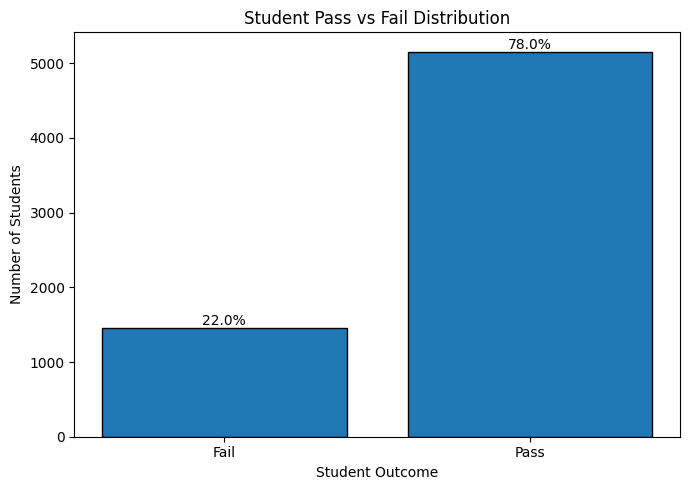

In [ ]:


plt.figure(figsize=(7, 5))

bars = plt.bar(
    class_balance["Class"],
    class_balance["Count"],
    edgecolor="black"
)

plt.title("Student Pass vs Fail Distribution")
plt.xlabel("Student Outcome")
plt.ylabel("Number of Students")

for bar, percentage in zip(bars, class_balance["Percentage"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

##Numerical Univariant Analysis (Histograms)

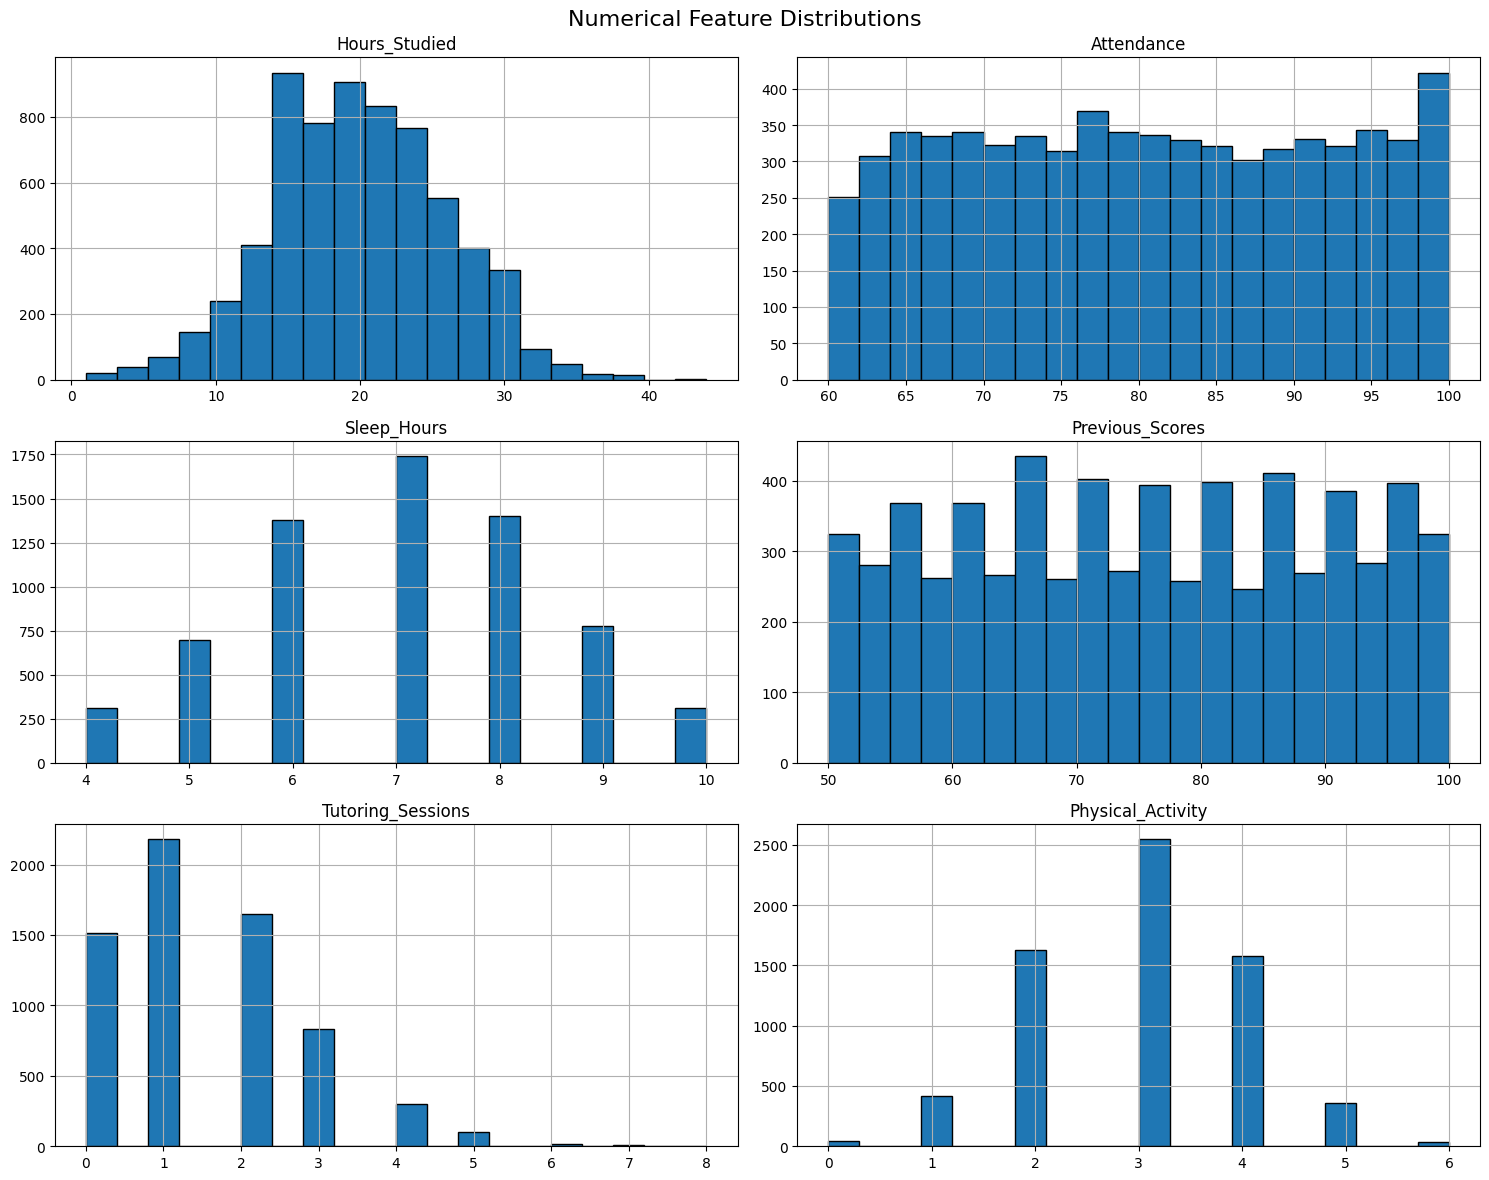

In [ ]:

numeric_eda_cols = [
    col for col in numerical_cols
    if col != "Exam_Score"
]

df_raw[numeric_eda_cols].hist(
    figsize=(15, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Numerical Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

## Numerical Univariate Analysis (Boxplots)

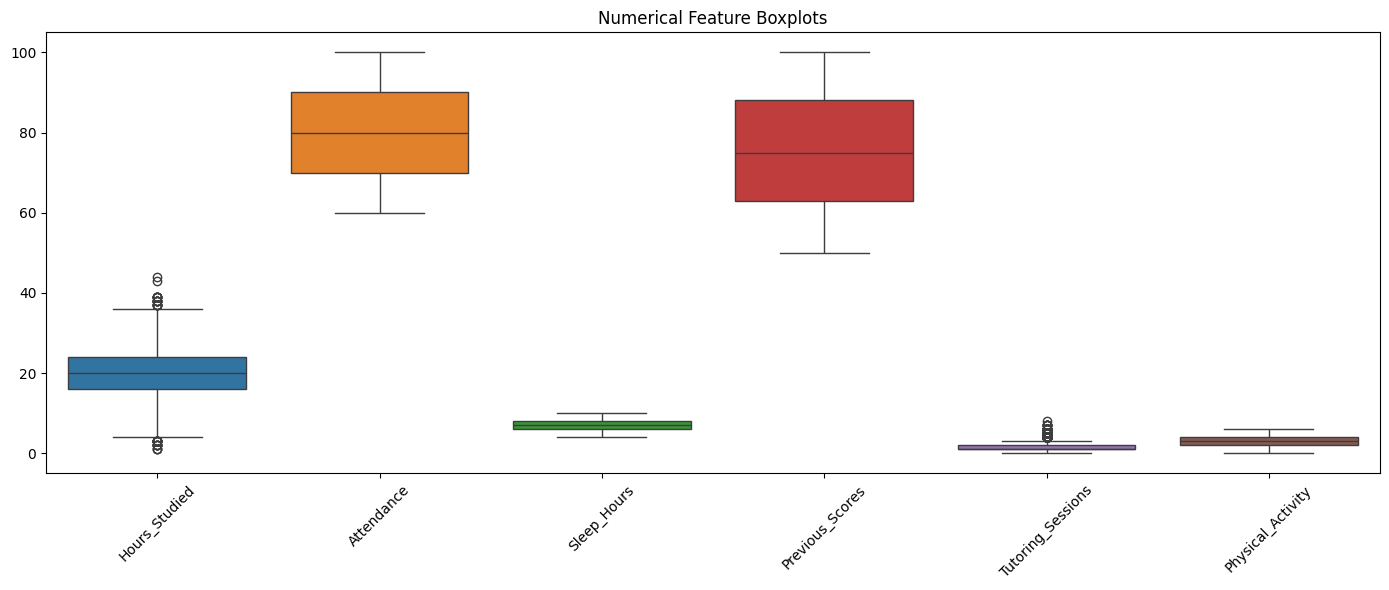

In [ ]:

plt.figure(figsize=(14, 6))

sns.boxplot(data=df_raw[numeric_eda_cols])

plt.title("Numerical Feature Boxplots")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Categorical Univariate Analysis

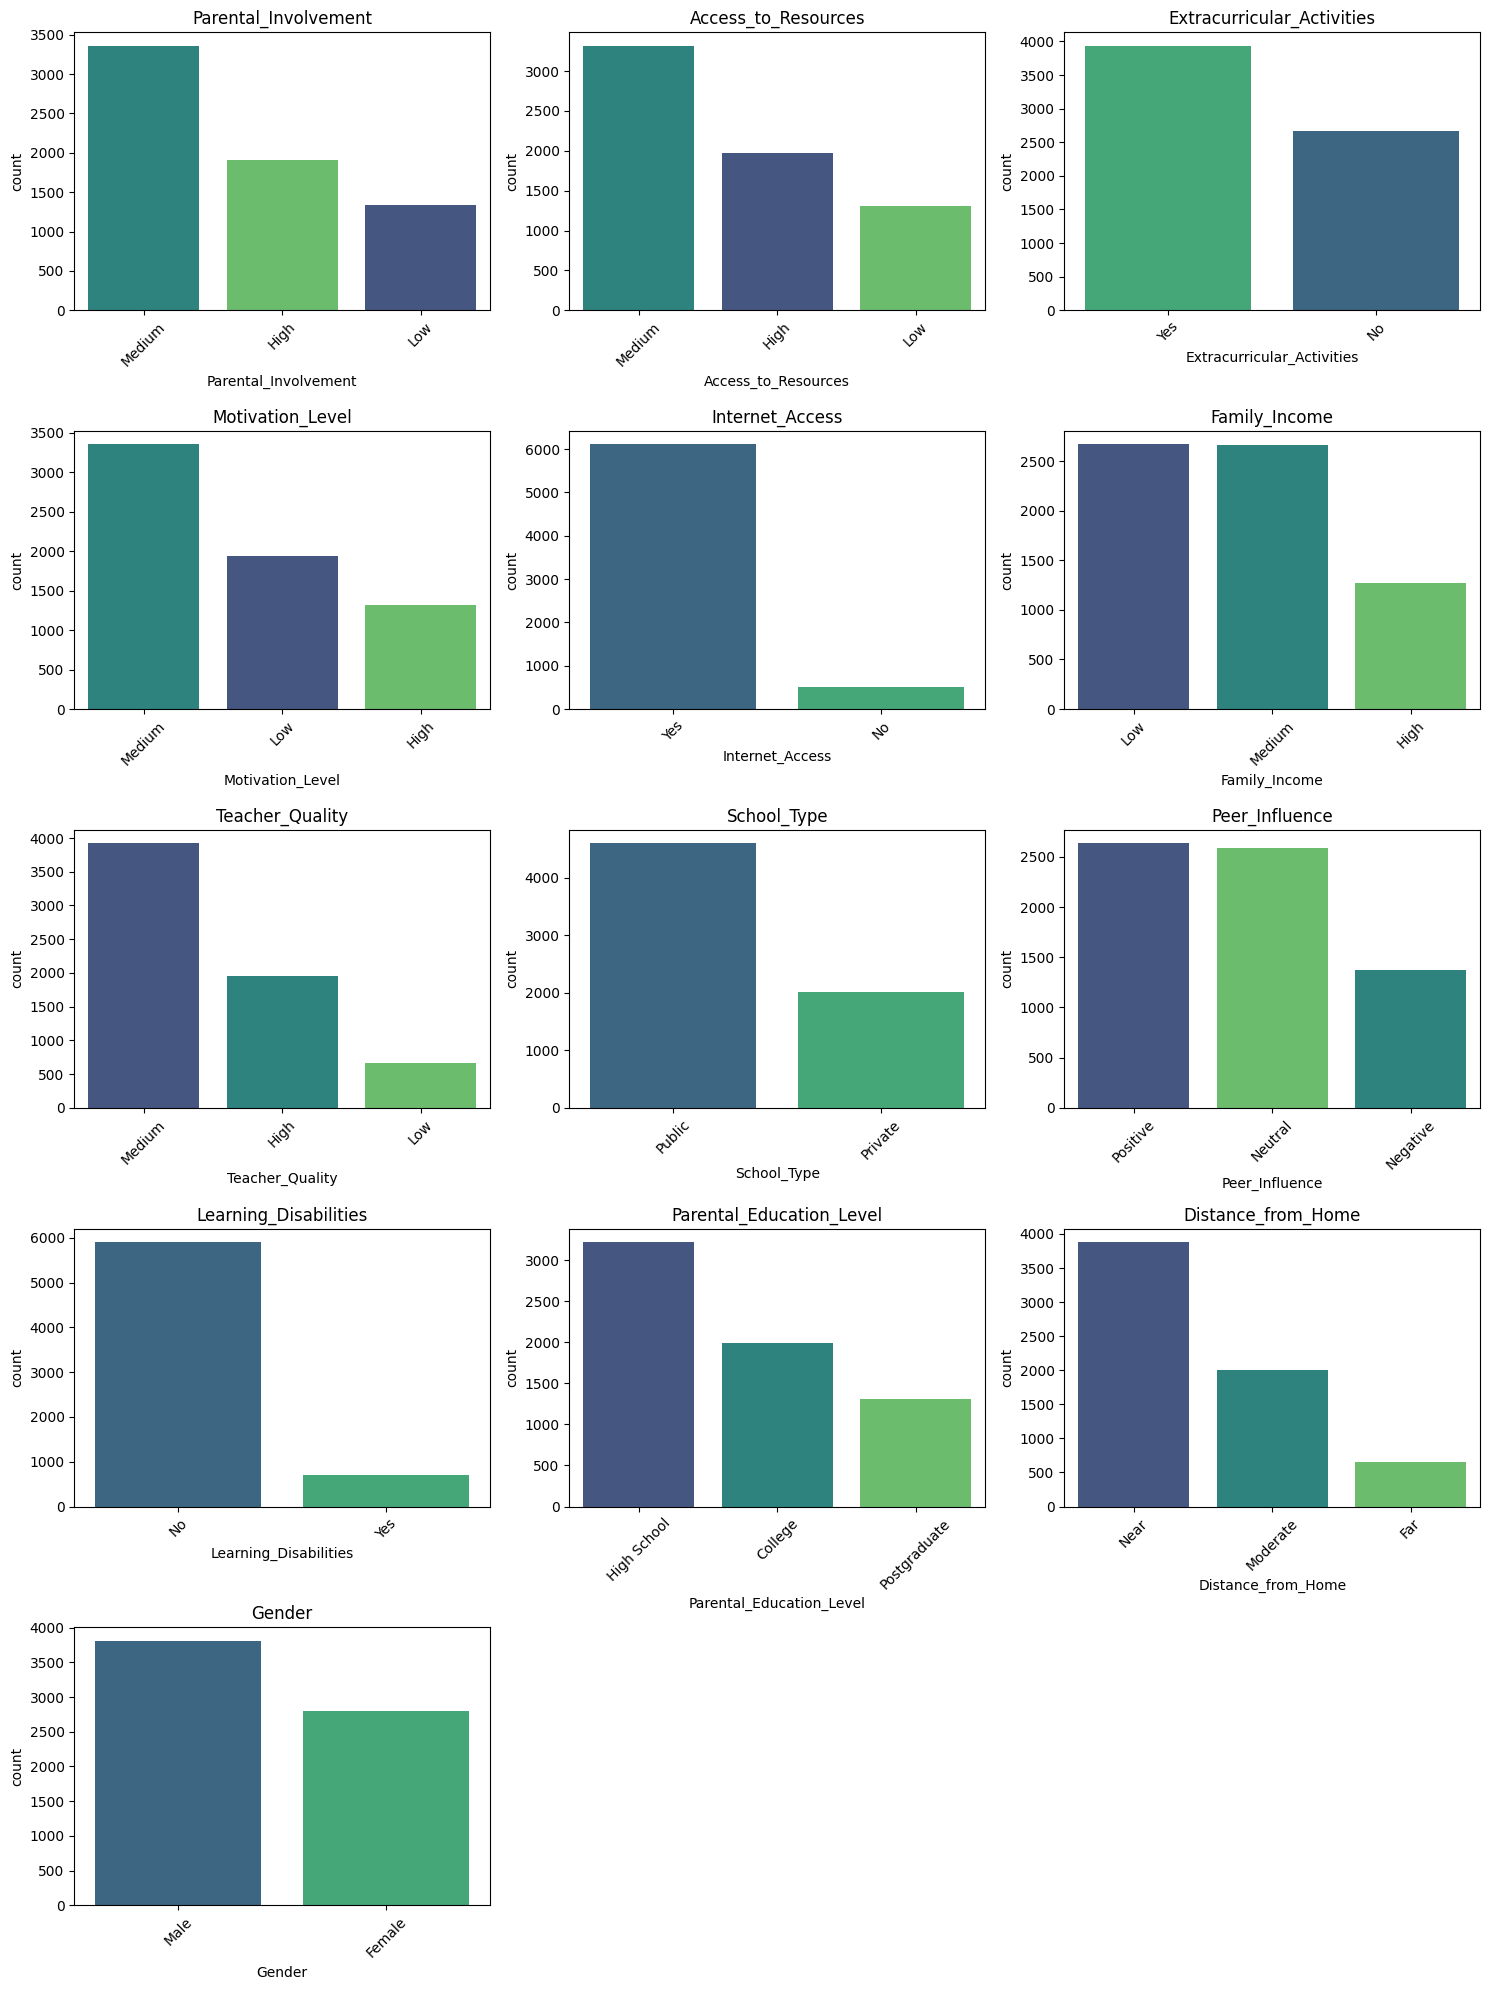

In [ ]:
import math

n_cols = 3
n_rows = math.ceil(len(categorical_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))

for ax, col in zip(axes.flatten(), categorical_cols):
    sns.countplot(
        data=df_raw, x=col, order=df_raw[col].value_counts().index,
        hue=col, palette="viridis", legend=False, ax=ax
    )
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

for ax in axes.flatten()[len(categorical_cols):]: ax.remove()

plt.tight_layout()
plt.show()




##Bivariate Analysis: Numerical Features vs Pass/Fail

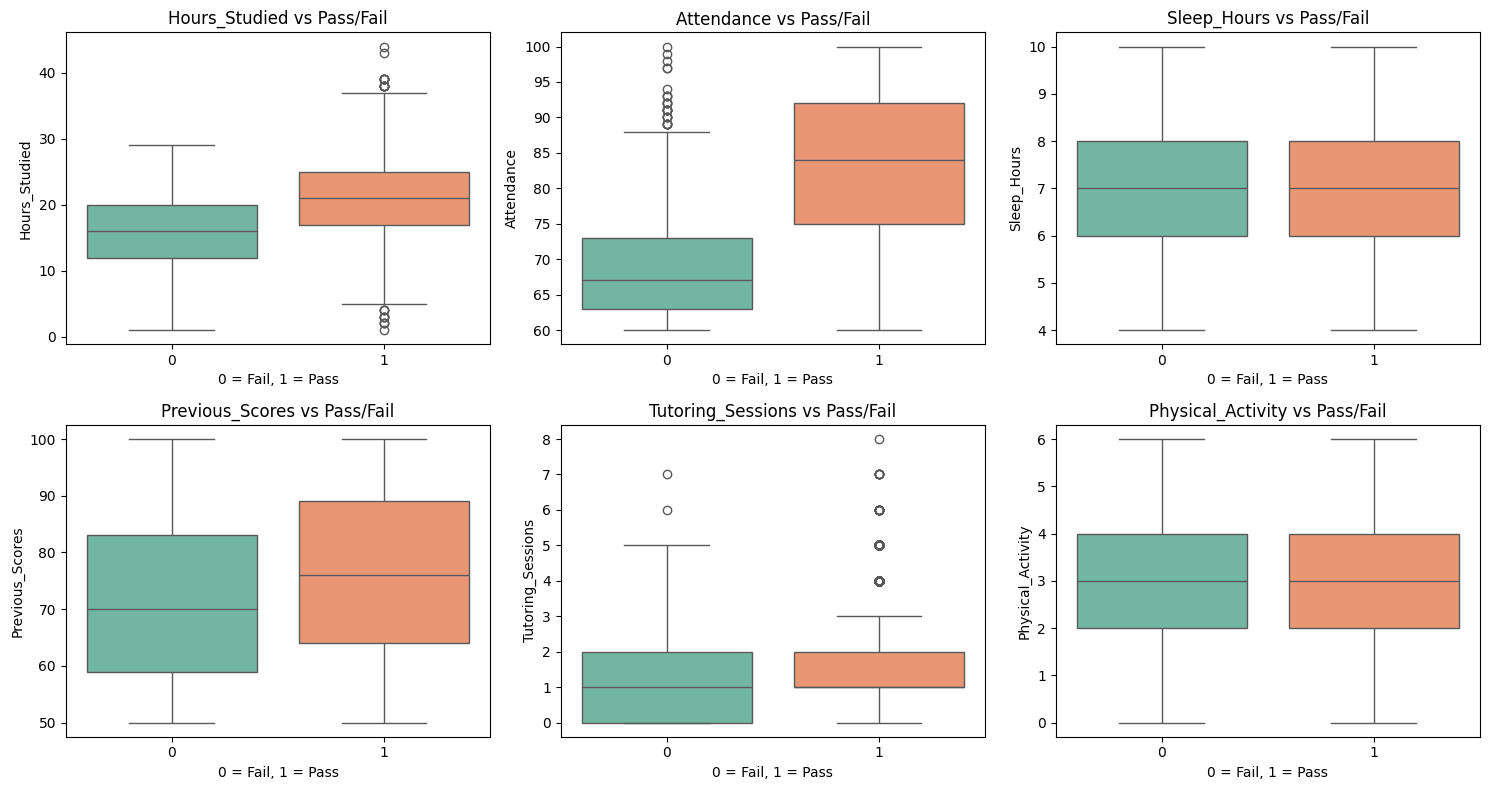

In [ ]:

numeric_bivariate_cols = [col for col in numerical_cols if col != "Exam_Score"]

n_cols = 3
n_rows = math.ceil(len(numeric_bivariate_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))

for ax, col in zip(axes.flatten(), numeric_bivariate_cols):
    sns.boxplot(
        data=df_raw, x="Pass_Fail", y=col,
        hue="Pass_Fail", palette="Set2", legend=False, ax=ax
    )
    ax.set_title(f"{col} vs Pass/Fail")
    ax.set_xlabel("0 = Fail, 1 = Pass")

for ax in axes.flatten()[len(numeric_bivariate_cols):]: ax.remove()

plt.tight_layout()
plt.show()


## Bivariate Analysis: Categorical Features vs Pass/Fail

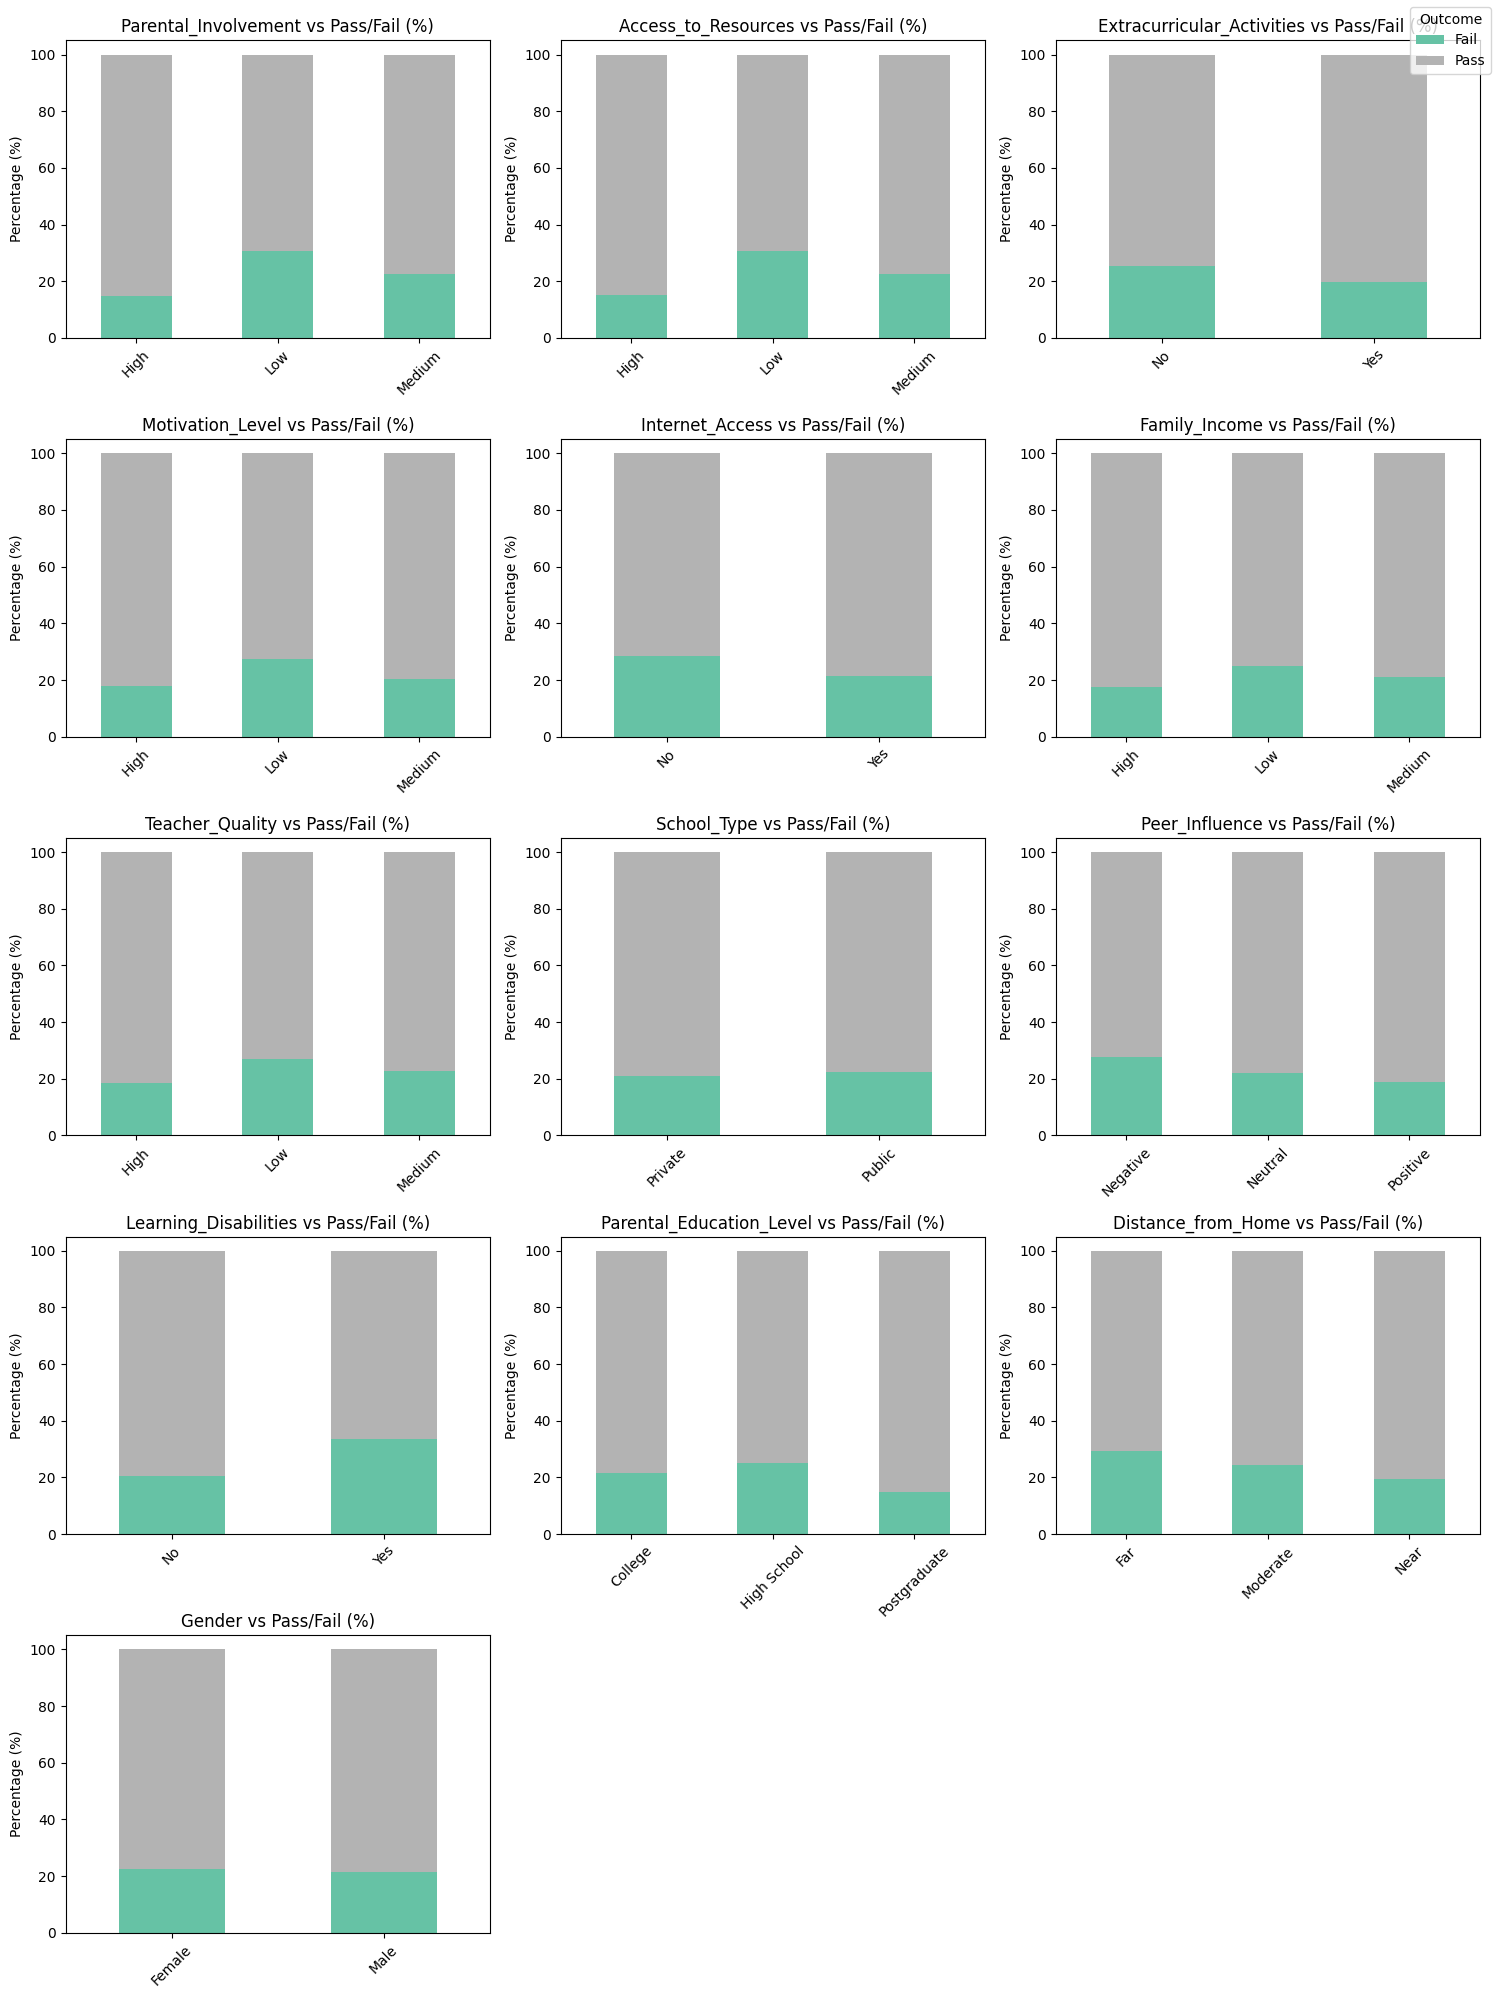

In [ ]:


n_cols = 3
n_rows = math.ceil(len(categorical_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))

for ax, col in zip(axes.flatten(), categorical_cols):
    cross_tab = pd.crosstab(df_raw[col], df_raw["Pass_Fail"], normalize="index") * 100
    cross_tab.plot(kind="bar", stacked=True, colormap="Set2", ax=ax, legend=False)

    ax.set_title(f"{col} vs Pass/Fail (%)")
    ax.set_xlabel("")
    ax.set_ylabel("Percentage (%)")
    ax.tick_params(axis="x", rotation=45)

# Poore figure ke liye sirf 1 common legend upar lagane ke liye:
fig.legend(["Fail", "Pass"], title="Outcome", loc="upper right")

for ax in axes.flatten()[len(categorical_cols):]: ax.remove()

plt.tight_layout()
plt.show()


## Correlation Analysis

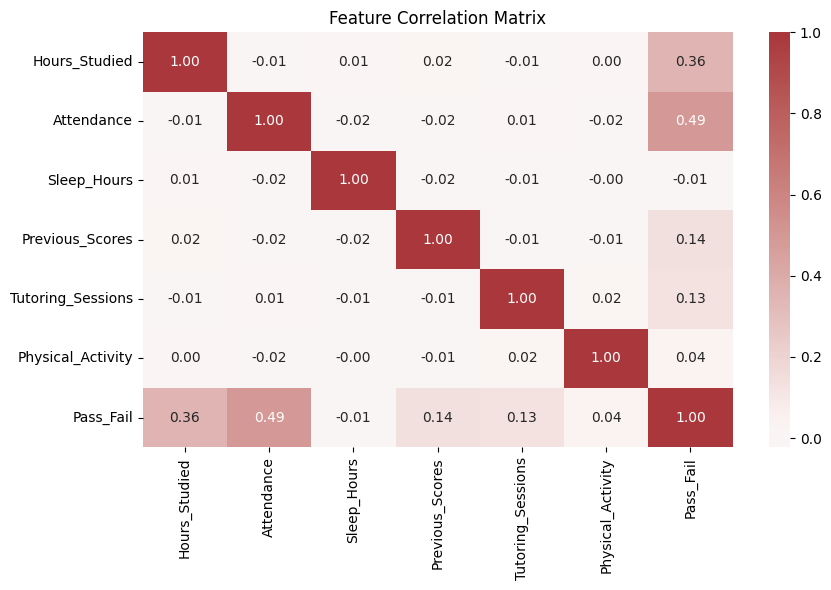

In [ ]:


correlation_cols = numeric_bivariate_cols + ["Pass_Fail"]

correlation_matrix = df_raw[correlation_cols].corr()

plt.figure(figsize=(9,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="vlag",
    fmt=".2f",
    center=0
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

##EDA Findings Summary

In [ ]:
eda_findings = {
    "Target Definition": "Pass_Fail derived from Exam_Score",
    "Passing Threshold": 65,  # Provisional
    "Score Distribution": "Reviewed in previous analysis",
    "Missing Values": "3 columns contain missing values",
    "Duplicates": "0 duplicate rows found",
    "Class Balance": "Checked and verified",
    "Numerical Patterns": "Analyzed",
    "Categorical Patterns": "Analyzed",
    "Feature-Target Relationships": "Evaluated",
    "Correlation Findings": "Reviewed via heatmap",
}

for finding, status in eda_findings.items():
    print(f"{finding}: {status}")

Target Definition: Pass_Fail derived from Exam_Score
Passing Threshold: 65
Score Distribution: Reviewed in previous analysis
Missing Values: 3 columns contain missing values
Duplicates: 0 duplicate rows found
Class Balance: Checked and verified
Numerical Patterns: Analyzed
Categorical Patterns: Analyzed
Feature-Target Relationships: Evaluated
Correlation Findings: Reviewed via heatmap


## Data Cleaning and Validation

In [ ]:
#  Whitespace Cleaning not required here but if we change dataset a little bit

for col in categorical_cols:
    df_raw[col] = df_raw[col].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

print("Whitespace cleaning completed.")

Whitespace cleaning completed.


In [ ]:
# Target Integrity Verification

expected_target = (df_raw["Exam_Score"] >= pass_threshold).astype(int)

mismatch_count = (df_raw["Pass_Fail"] != expected_target).sum()

assert mismatch_count == 0, "Target labels do not match the threshold!"

print("Target integrity verified.")
print(f"Threshold: {pass_threshold}")
print(f"Total mismatches: {mismatch_count}")

Target integrity verified.
Threshold: 65
Total mismatches: 0


**missing values ko train-test split k bad handle kary data leakage se prevent karny k liay**

##ML Data Preparation

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# Feature-Target Separation

X = df_raw.drop(columns=["Exam_Score", "Pass_Fail"])
y = df_raw["Pass_Fail"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5285, 19)
Testing Features: (1322, 19)
Training Target: (5285,)
Testing Target: (1322,)


In [ ]:
#  Target Distribution Verification

split_distribution = pd.DataFrame({
    "Full Dataset": y.value_counts(normalize=True),
    "Training Set": y_train.value_counts(normalize=True),
    "Testing Set": y_test.value_counts(normalize=True)
}).fillna(0).mul(100).round(2)

display(split_distribution)

,Full Dataset,Training Set,Testing Set
Pass_Fail,,,
1,78.02,78.03,77.99
0,21.98,21.97,22.01


In [ ]:
# Prepare feature groups
numerical_cols=[col for col in numerical_cols if col in X.columns]
categorical_cols=[col for col in categorical_cols if col in X.columns]

assert set(numerical_cols).isdisjoint(set(categorical_cols)),\
"Numerical and categorical columns overlap!"

assert set(numerical_cols + categorical_cols)== set(X.columns),\
"Some features are missing from feature groups!"

print("\nFeature groups aligned successfully.")



Feature groups aligned successfully.


In [ ]:
# — Import preprocessing tools

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Preprocessing tools imported successfully.")

Preprocessing tools imported successfully.


In [ ]:
#  — Numerical pipeline

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical pipeline created.")

#  — Categorical pipeline

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical pipeline created.")


# —  Combine preprocessing pipelines

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Combined preprocessor created successfully.")

Numerical pipeline created.
Categorical pipeline created.
Combined preprocessor created successfully.


In [ ]:
X_train_processed=preprocessor.fit_transform(X_train)
X_test_processed=preprocessor.transform(X_test)
print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Processed training shape: (5285, 40)
Processed testing shape: (1322, 40)


In [ ]:
# — Validate processed data

from scipy.sparse import issparse

# Check for missing or infinite values
if issparse(X_train_processed):
    train_valid = np.isfinite(X_train_processed.data).all()
else:
    train_valid = np.isfinite(X_train_processed).all()

if issparse(X_test_processed):
    test_valid = np.isfinite(X_test_processed.data).all()
else:
    test_valid = np.isfinite(X_test_processed).all()

print("Training data contains only finite values:", train_valid)
print("Testing data contains only finite values:", test_valid)

Training data contains only finite values: True
Testing data contains only finite values: True


## Model Training

**Logistic Regression**

In [ ]:
#  — Import Logistic Regression & evaluation metrics

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
   ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer

print("Model and evaluation metrics imported successfully.")

Model and evaluation metrics imported successfully.


In [ ]:
#  — Initialize Logistic Regression
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear'],
}

log_reg= GridSearchCV(
    LogisticRegression(class_weight='balanced'),
    param_grid,
    cv=5,
    scoring='f1',
)
# log_reg = LogisticRegression(
#      C=0.1,
#     class_weight="balanced",
#     max_iter=1000,
#     random_state=42
# )

log_reg.fit(X_train_processed, y_train)
y_pred = log_reg.predict(X_test_processed)
accuracy = accuracy_score(y_test, y_pred)

print('Best Parameters:', log_reg.best_params_)
print('Best F1 Score:',log_reg.best_score_)

fail_precision = precision_score(y_test, y_pred, pos_label=0)
fail_recall = recall_score(y_test, y_pred, pos_label=0)
fail_f1 = f1_score(y_test, y_pred, pos_label=0)

print("Accuracy     :", round(accuracy, 4))
print("Fail Precision:", round(fail_precision, 4))
print("Fail Recall   :", round(fail_recall, 4))
print("Fail F1-score :", round(fail_f1, 4))

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fail", "Pass"]
))

Best Parameters: {'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}
Best F1 Score: 0.9867762292765377
Accuracy     : 0.9834
Fail Precision: 0.9325
Fail Recall   : 0.9966
Fail F1-score : 0.9635
              precision    recall  f1-score   support

        Fail       0.93      1.00      0.96       291
        Pass       1.00      0.98      0.99      1031

    accuracy                           0.98      1322
   macro avg       0.97      0.99      0.98      1322
weighted avg       0.98      0.98      0.98      1322



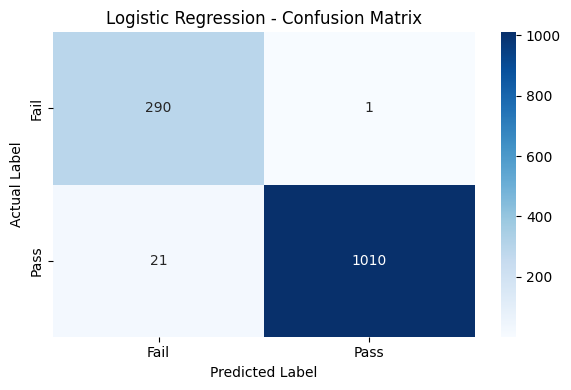

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression - Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
# this is to check any data leakage due to high model accuracy

print("Target column:", y.name)
print("\nFeature columns:")
print(X.columns.tolist())

suspected_columns = [
    col for col in X.columns
    if any(keyword in col.lower()
           for keyword in ["score", "pass_fail", "result", "grade"])
]

print("\nPotentially suspicious columns:")
print(suspected_columns)

Target column: Pass_Fail

Feature columns:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Potentially suspicious columns:
['Previous_Scores']


**Decision Tree**

In [ ]:
# Training and predicting dt model
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_processed, y_train)
y_pred_dt = dt_model.predict(X_test_processed)

dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt, zero_division=0)
dt_recall = recall_score(y_test, y_pred_dt, zero_division=0)
dt_f1 = f1_score(y_test, y_pred_dt, zero_division=0)

print("Decision Tree Evaluation")
print("-" * 35)
print(f"Accuracy  : {dt_accuracy:.4f}")
print(f"Precision : {dt_precision:.4f}")
print(f"Recall    : {dt_recall:.4f}")
print(f"F1 Score  : {dt_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

Decision Tree Evaluation
-----------------------------------
Accuracy  : 0.8684
Precision : 0.9108
Recall    : 0.9214
F1 Score  : 0.9161

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.68      0.69       291
           1       0.91      0.92      0.92      1031

    accuracy                           0.87      1322
   macro avg       0.81      0.80      0.81      1322
weighted avg       0.87      0.87      0.87      1322



Confusion Matrix:
[[198  93]
 [ 81 950]]


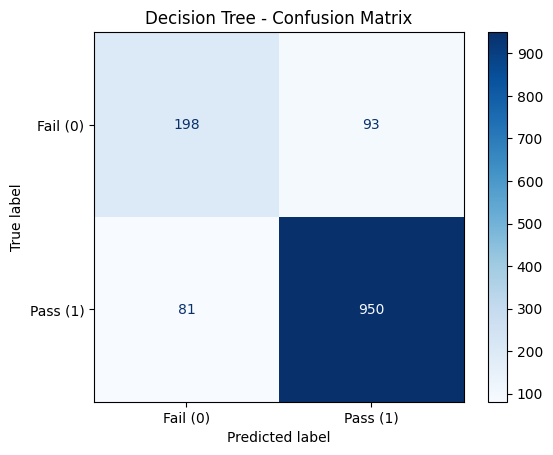

In [ ]:
#— Decision Tree Confusion Matrix

cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Confusion Matrix:")
print(cm_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["Fail (0)", "Pass (1)"]
)

disp.plot(cmap="Blues")
plt.title("Decision Tree - Confusion Matrix")
plt.show()

Top 15 Important Features:
                       Feature  Importance
               num__Attendance    0.335604
            num__Hours_Studied    0.224372
          num__Previous_Scores    0.086550
        num__Tutoring_Sessions    0.044162
        num__Physical_Activity    0.033388
  cat__Access_to_Resources_Low    0.025862
 cat__Parental_Involvement_Low    0.025842
              num__Sleep_Hours    0.023286
       cat__Family_Income_High    0.017926
cat__Parental_Involvement_High    0.016527
     cat__Motivation_Level_Low    0.012285
 cat__Access_to_Resources_High    0.011720
  cat__Distance_from_Home_Near    0.011297
    cat__Motivation_Level_High    0.011260
     cat__Teacher_Quality_High    0.010838


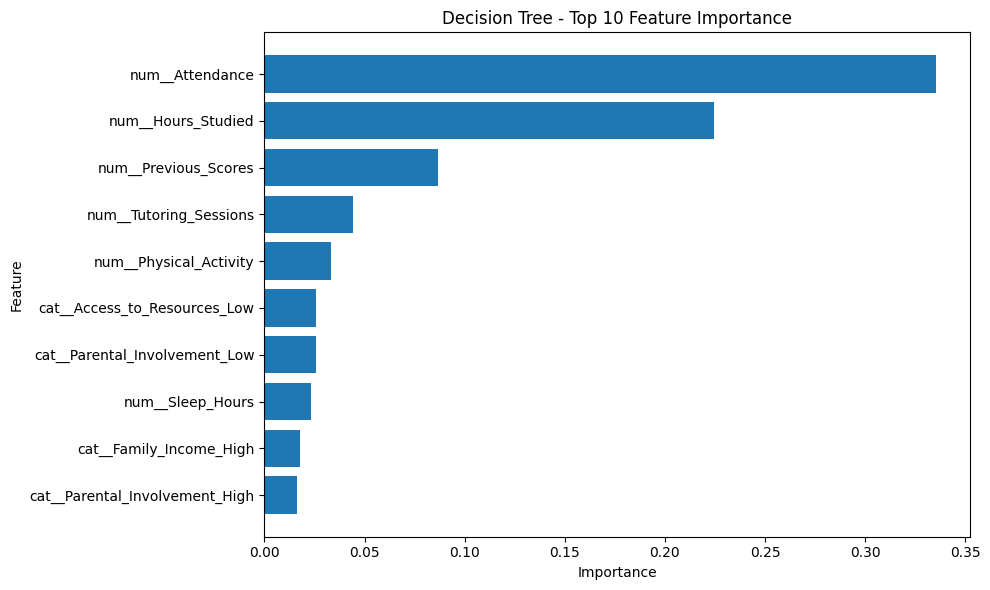

In [ ]:
#  Decision Tree Feature Importance


feature_names = preprocessor.get_feature_names_out()

importance_values = dt_model.feature_importances_

# Create DataFrame
feature_importance_dt = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

feature_importance_dt = feature_importance_dt.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
print(feature_importance_dt.head(15).to_string(index=False))

top_10 = feature_importance_dt.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))

plt.barh(
    top_10["Feature"],
    top_10["Importance"]
)

plt.title("Decision Tree - Top 10 Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

**Random Forest**

In [ ]:
#— Train Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)
y_pred_rf = rf_model.predict(X_test_processed)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)

print("Random Forest Evaluation")
print("-" * 35)
print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1 Score  : {rf_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Random Forest Evaluation
-----------------------------------
Accuracy  : 0.9047
Precision : 0.8987
Recall    : 0.9893
F1 Score  : 0.9418

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.60      0.74       291
           1       0.90      0.99      0.94      1031

    accuracy                           0.90      1322
   macro avg       0.92      0.80      0.84      1322
weighted avg       0.91      0.90      0.90      1322



Confusion Matrix:
[[ 176  115]
 [  11 1020]]


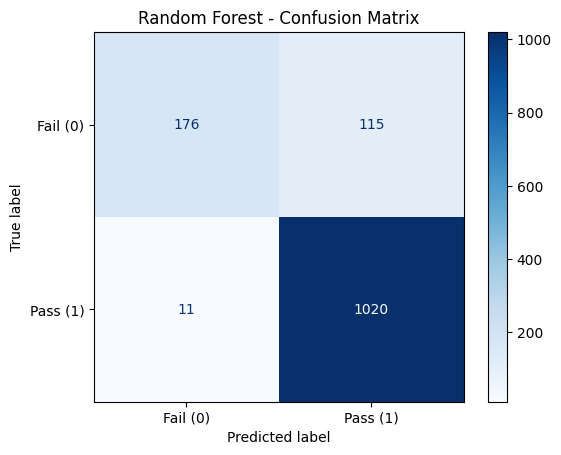

In [ ]:
# — Random Forest Confusion Matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Confusion Matrix:")
print(cm_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Fail (0)", "Pass (1)"]
)

disp.plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.show()

Top 15 Random Forest Features:
                       Feature  Importance
               num__Attendance    0.296313
            num__Hours_Studied    0.184667
          num__Previous_Scores    0.072924
        num__Tutoring_Sessions    0.036609
              num__Sleep_Hours    0.032237
        num__Physical_Activity    0.029912
  cat__Access_to_Resources_Low    0.015412
 cat__Parental_Involvement_Low    0.014887
cat__Parental_Involvement_High    0.013566
 cat__Access_to_Resources_High    0.013037
     cat__Motivation_Level_Low    0.012710
        cat__Family_Income_Low    0.012651
  cat__Peer_Influence_Positive    0.012088
  cat__Distance_from_Home_Near    0.011998
  cat__Peer_Influence_Negative    0.011605


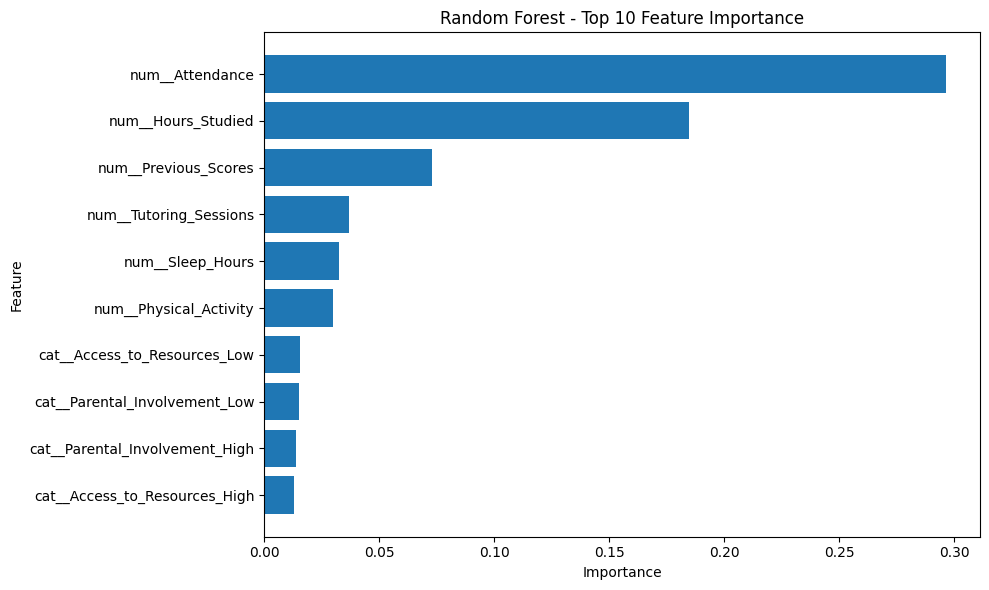

In [ ]:
#— Random Forest Feature Importance
feature_names = preprocessor.get_feature_names_out()

importance_values = rf_model.feature_importances_

feature_importance_rf = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

feature_importance_rf = feature_importance_rf.sort_values(
    by="Importance",
    ascending=False
)


print("Top 15 Random Forest Features:")
print(feature_importance_rf.head(15).to_string(index=False))

top_10_rf = feature_importance_rf.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_10_rf["Feature"], top_10_rf["Importance"])

plt.title("Random Forest - Top 10 Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

**Model Comparison**

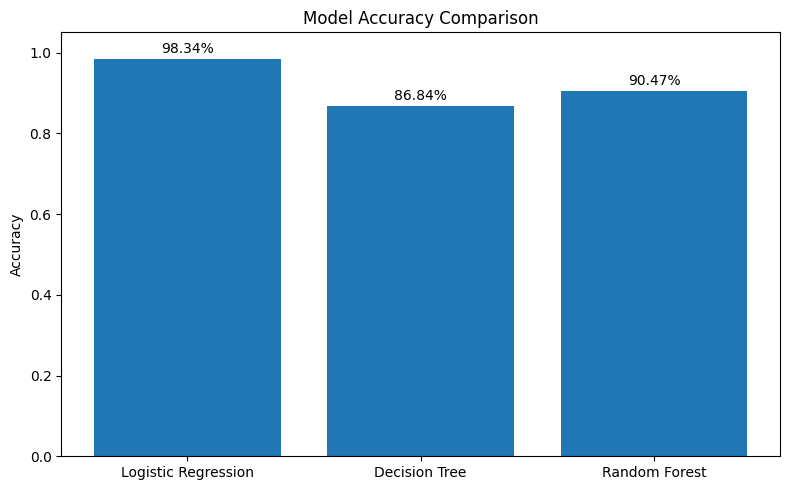

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.9826        NaN     NaN       NaN
1        Decision Tree    0.8684     0.9108  0.9214    0.9161
2        Random Forest    0.9047     0.8987  0.9893    0.9418


In [ ]:
#  — Compare Models



model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        0.9826,
        dt_accuracy,
        rf_accuracy
    ],
    "Precision": [
        None,
        dt_precision,
        rf_precision
    ],
    "Recall": [
        None,
        dt_recall,
        rf_recall
    ],
    "F1 Score": [
        None,
        dt_f1,
        rf_f1
    ]
})

# — Model Accuracy Comparison

model_names = ["Logistic Regression", "Decision Tree", "Random Forest"]
accuracies = [accuracy, dt_accuracy, rf_accuracy]

plt.figure(figsize=(8, 5))

bars = plt.bar(model_names, accuracies)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)


for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.015,
        f"{height * 100:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

print(model_comparison.round(4))

In [ ]:
#  — Final Model Comparison

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

model_predictions = {
    " Logistic Regression": y_pred,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,

}

comparison_results = []

for model_name, predictions in model_predictions.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Fail Precision": precision_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Fail Recall": recall_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Fail F1": f1_score(
            y_test, predictions, pos_label=0, zero_division=0
        )
    })

final_comparison = pd.DataFrame(comparison_results)

display(
    final_comparison
    .sort_values(by="Fail F1", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

,Model,Accuracy,Fail Precision,Fail Recall,Fail F1
0,Logistic Regression,0.9834,0.9325,0.9966,0.9635
1,Random Forest,0.9047,0.9412,0.6048,0.7364
2,Decision Tree,0.8684,0.7097,0.6804,0.6947


#Final Model Selection

Based on the current model comparison, Logistic Regression is the leading candidate for the Student Performance Risk Prediction System.

It achieved an accuracy of 98.34%, a Fail Precision of 93.25%, a Fail Recall of 99.66%, and a Fail F1-score of 96.35%.

Since the primary objective of this project is to identify students at risk of failing, Fail Recall is prioritized while maintaining a strong Fail F1-score.

Logistic Regression is provisionally selected for deployment, subject to comparison with the Balanced and GridSearchCV-tuned Logistic Regression variants and final validation.

In [ ]:
# — Save Final Selected Model

import joblib
import os

# Create folder to store ML artifacts
os.makedirs("artifacts", exist_ok=True)

# Extract best model from GridSearchCV
best_model = log_reg.best_estimator_

# Save model + preprocessor + metadata
model_artifact = {
    "model": best_model,
    "preprocessor": preprocessor,
    "model_name": "Logistic Regression (GridSearchCV)",
    "features": list(X.columns),
    "target_mapping": {
        0: "Fail",
        1: "Pass"
    }
}

# Save artifact
joblib.dump(
    model_artifact,
    "artifacts/student_performance_model.joblib"
)

print("Model saved successfully!")
print("Best Parameters:", log_reg.best_params_)
print("Saved File: artifacts/student_performance_model.joblib")

Model saved successfully!
Best Parameters: {'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}
Saved File: artifacts/student_performance_model.joblib


In [ ]:
#  — Load and Verify Model

import joblib

# Load saved artifact
loaded_artifact = joblib.load(
    "artifacts/student_performance_model.joblib"
)

# Extract components
loaded_model = loaded_artifact["model"]
loaded_preprocessor = loaded_artifact["preprocessor"]

print("Model Loaded Successfully!")
print("Model Name:", loaded_artifact["model_name"])
print("Features Count:", len(loaded_artifact["features"]))
print("Target Mapping:", loaded_artifact["target_mapping"])
print("Best Parameters:", log_reg.best_params_)

Model Loaded Successfully!
Model Name: Logistic Regression (GridSearchCV)
Features Count: 19
Target Mapping: {0: 'Fail', 1: 'Pass'}
Best Parameters: {'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}


In [ ]:
#  — Prediction Test

# Take one raw student record
sample_student = X_test.iloc[[0]].copy()

# Maintain correct feature order
sample_student = sample_student[loaded_artifact["features"]]

# Preprocess raw input
sample_processed = loaded_preprocessor.transform(sample_student)

# Predict class
prediction = loaded_model.predict(sample_processed)[0]

# Predict probability
probabilities = loaded_model.predict_proba(sample_processed)[0]

# Convert numeric output to readable label
predicted_label = (
    "Pass" if prediction == 1 else "Fail"
)

print("Predicted Result:", predicted_label)
print("-" * 30)

for class_label, probability in zip(
    loaded_model.classes_,
    probabilities
):
    label = "Pass" if class_label == 1 else "Fail"
    print(f"{label} Probability: {probability:.2%}")

Predicted Result: Fail
------------------------------
Fail Probability: 98.11%
Pass Probability: 1.89%


In [ ]:
#  — Prediction Consistency Check

original_prediction = log_reg.predict(X_test_processed[:1])[0]
saved_prediction = loaded_model.predict(sample_processed)[0]

print("Original Prediction:", original_prediction)
print("Saved Prediction:", saved_prediction)

assert original_prediction == saved_prediction

print("Consistency Check Passed!")

Original Prediction: 0
Saved Prediction: 0
Consistency Check Passed!
